In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, gc, random, logging
from collections import Counter

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1,2,3")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.append("../..")

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.models import ModelandTokenizer
from src.tokens import prepare_input
from src.functional import get_hs
from src.utils import env_utils, logging_utils
from src.goals.multiline_prompts import (
    build_example,
    replace_in_code_newline_with_tabnewline,
    VAR_LETTERS,
)


logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)


def rich_print(*a, **k):
    console.print(*a, **k)


logger = logging.getLogger(__name__)

# MODEL_NAME = "Qwen/Qwen2.5-Coder-14B-Instruct"
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

# regen vs cache: True -> always rebuild pairs + re-extract latents;  False -> load from local-disk cache when present
OVERWRITE = False

In [3]:
mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}")

2026-07-06 15:44:13 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


2026-07-06 15:44:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-06 15:44:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-06 15:44:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-06 15:44:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-06 15:44:14 httpx INFO     HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-32B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-07-06 15:44:14 httpx

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-06 15:44:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-06 15:44:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-06 15:44:24 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120


In [4]:
# ── local-disk cache for pairs + latents (gated by OVERWRITE from the setup cell) ──
import json, pickle, hashlib

CACHE_DIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multiline_signal",
                         MODEL_NAME.split("/")[-1], "cache")
os.makedirs(CACHE_DIR, exist_ok=True)

# general scratch cache for things we (re)run inside the notebook (gated by OVERWRITE)
NB_CACHE_DIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_cache")
os.makedirs(NB_CACHE_DIR, exist_ok=True)


def _key(**cfg):
    """Short stable hash of every config field that changes the cached data."""
    return hashlib.md5(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:10]


def cache_path(kind, ext, **cfg):
    return os.path.join(CACHE_DIR, f"{kind}_{cfg.get('mode', '')}_{_key(**cfg)}.{ext}")


def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)


def save_pickle(obj, path):
    with open(path, "wb") as f:
        pickle.dump(obj, f)


print(f"cache dir: {CACHE_DIR}\nnb cache: {NB_CACHE_DIR}\nOVERWRITE = {OVERWRITE}")

cache dir: /disk/u/arnab/Codes/Projects/goals/results/multiline_signal/Qwen2.5-Coder-32B-Instruct/cache
nb cache: /disk/u/arnab/Codes/Projects/goals/results/notebook_cache
OVERWRITE = False


# 04.3 · Learning a **stop** / **continue** signal (mass-mean-diff)

Reuses the forced-prefill prompt setup from `04.2_multiline.ipynb` (`src.goals.multiline_prompts`).

**Idea.** At the pivot (the trailing whitespace right after the target condition's prefill) the LM
is either:
- **continue** — it was given the target's *incomplete* first line (`multiline` style) and should
  keep evaluating the same variable, or
- **stop / move-on** — it was given a *complete* one-liner (`singleline` style) and should move to
  the next variable.

We look for a single linear direction that captures this *intent*, invariant to the concrete
predicate. Following the TODO:

- **v_stop** = `E[h_singleline − h_multiline]`  (points toward "stop / move on")
- **v_continue** = `−v_stop`

`h_*` is the residual-stream latent at a fixed token position (`-1` / `-2`) under each prefill.

**This notebook (mass-mean-diff, the simple thing first):** build minimal contrastive pairs →
extract latents (batched) → check separability with PCA + a linear probe → form `v_stop` /
`v_continue`. The causal steering test is scaffolded at the end (TODO).

## 1. Contrastive pairs (singleline ↔ multiline)

Each pair shares **one per-pair seed**, so both members get identical predicates / params / priors
and differ *only* at the target condition's prefill style. That makes them true **minimal pairs**:
the latent difference isolates the stop-vs-continue intent, not the surrounding content.

In [ ]:
# ── build (or load) minimal contrastive pairs: SAME conditions, target rendered two ways ──
SEED        = 0
N_PER_SLOT  = 2000                # pairs per target slot
SLOTS       = [1, 2, 3]          # target = b, c, d  (priors < k are complete, >=1 multiline)
PROMPT_MODE = "chat"             # "chat" | "fim"
POS         = -2                 # latent token position (-1 / -2: trailing whitespace at the pivot)

pairs_cfg = dict(model=MODEL_NAME, seed=SEED, n_per_slot=N_PER_SLOT, slots=SLOTS, mode=PROMPT_MODE)
pairs_fp  = cache_path("pairs", "pkl", **pairs_cfg)

if not OVERWRITE and os.path.exists(pairs_fp):
    pairs = load_pickle(pairs_fp)
    print(f"[cache] loaded {len(pairs)} pairs <- {os.path.basename(pairs_fp)}")
else:
    base_rng = random.Random(SEED)
    pairs = []
    for k in SLOTS:
        for _ in range(N_PER_SLOT):
            seed = base_rng.randrange(2 ** 31)
            ml = build_example(mt, random.Random(seed), target_slot=k, n_conditions=k + 2,
                               mode=PROMPT_MODE, style="multiline")    # incomplete -> continue
            sl = build_example(mt, random.Random(seed), target_slot=k, n_conditions=k + 2,
                               mode=PROMPT_MODE, style="singleline")   # complete   -> stop / move-on
            # tokenization-stable prompt (used for extraction); pad trailing whitespace at the pivot
            ml["prompt"] = replace_in_code_newline_with_tabnewline(ml["full_prompt"]) + "   "
            sl["prompt"] = replace_in_code_newline_with_tabnewline(sl["full_prompt"]) + "   "
            pairs.append({"slot": k, "ml": ml, "sl": sl})
    save_pickle(pairs, pairs_fp)
    print(f"[gen] built {len(pairs)} pairs -> {os.path.basename(pairs_fp)}")

print(f"[{PROMPT_MODE}] {len(pairs)} contrastive pairs"
      f"  | slots: {dict(Counter(p['slot'] for p in pairs))}")

In [ ]:
# sanity: members should share the token at POS (so v_stop reflects upstream intent, not the
# surface token). Report the match rate; show one pair's two target lines.
def tok_at(prompt, pos):
    ids = prepare_input(prompt, tokenizer=mt, padding_side="left")["input_ids"][0]
    return mt.tokenizer.decode(ids[pos].item())

match = sum(tok_at(p["sl"]["prompt"], POS) == tok_at(p["ml"]["prompt"], POS) for p in pairs)
print(f"POS={POS} token-aligned pairs: {match}/{len(pairs)}")

e = pairs[0]
rich_print(f"[bold]slot[/bold]={e['slot']}  target_var={e['ml']['target_var']}  "
           f"pred={e['ml']['target_pred']}")
rich_print("[green]── multiline (continue): forced INCOMPLETE first line ──[/green]")
rich_print(escape(e["ml"]["target_first_line"]))
rich_print("[red]── singleline (stop): forced COMPLETE one-liner ──[/red]")
rich_print(escape(e["sl"]["target_first_line"]))

## 2. Extract latents (batched, all residual layers)

One forward pass per batch reads every residual layer at `POS`. Left-padding keeps the negative
`POS` aligned to the same real token across the batch.

In [ ]:
from tqdm.auto import tqdm

# ── batched latent extraction over ALL residual layers at POS (cached) ──────
LAYERS = list(range(mt.n_layer))
BATCH  = 32

@torch.no_grad()
def extract_latents(prompts, layers, pos, batch_size=BATCH):
    """Residual-stream latents at one token position. Returns (n_prompts, n_layers, d) float32.
    Relies on left-padding so a negative `pos` aligns to the same real token across the batch."""
    locs = [(mt.layer_name_format.format(L), pos) for L in layers]
    out = np.empty((len(prompts), len(layers), mt.n_embd), dtype=np.float32)
    for b0 in tqdm(range(0, len(prompts), batch_size), desc="Extracting latents"):
        chunk = prompts[b0:b0 + batch_size]
        tok = prepare_input(chunk, tokenizer=mt, padding_side="left")
        hs = get_hs(mt=mt, input=tok, locations=locs, return_dict=True)
        for li, L in enumerate(layers):
            h = hs[(mt.layer_name_format.format(L), pos)]
            if h.ndim == 1:
                h = h.unsqueeze(0)
            out[b0:b0 + len(chunk), li] = h.float().cpu().numpy()
        del hs
        gc.collect()
    return out

lat_cfg = dict(**pairs_cfg, pos=POS, n_layer=mt.n_layer)
lat_fp  = cache_path("latents", "npz", **lat_cfg)

if not OVERWRITE and os.path.exists(lat_fp):
    z = np.load(lat_fp)
    H_sl, H_ml = z["H_sl"], z["H_ml"]
    print(f"[cache] loaded latents {H_sl.shape} <- {os.path.basename(lat_fp)}")
else:
    H_sl = extract_latents([p["sl"]["prompt"] for p in pairs], LAYERS, POS)   # stop class (+)
    H_ml = extract_latents([p["ml"]["prompt"] for p in pairs], LAYERS, POS)   # continue class (-)
    np.savez(lat_fp, H_sl=H_sl, H_ml=H_ml)
    print(f"[gen] extracted latents {H_sl.shape} -> {os.path.basename(lat_fp)}")

print("H_sl", H_sl.shape, "| H_ml", H_ml.shape)

## 3. Separability across layers (animated projection)

Replicates the contrastive-direction GIF from `03_probe.ipynb`. For every `LAYER_STEP`-th layer we
fit `v_stop` (paired mass-mean-diff) on a **train** split and, on the held-out **test** split, plot:

- **x** — projection onto `v_stop` (the stop ⇄ continue axis), with its ROC-AUC;
- **y** — top PC of the residual after removing `v_stop` (left-over off-axis structure), with its AUC.

A clean signal shows the two classes pulling apart along **x** (AUC → 1) over some band of layers,
with little separation remaining on **y**.

In [ ]:
# ── per-layer projection (replicates 03_probe), via src.analysis.algo ───────
# X_AXIS picks what the scatter x-axis shows:
#   "v_stop" -> projection onto v_stop (mass-mean-diff);  y = top residual PC
#   "v_cont" -> projection onto v_cont = -v_stop (mirror); y = top residual PC
#   "PC1"    -> plain 2D PCA of the latents: x = PC1, y = PC2
# AUC(stop) / best_layer are always read from the v_stop signal (ProjectionResult.auc_signal),
# independent of X_AXIS, so the table / best layer / saved signal stay comparable across modes.
from src.analysis.algo import projection_across_layers

X_AXIS       = "PC1"     # ["v_stop", "v_cont", "PC1"]
LAYER_STEP   = 4         # compute only every 4th layer (no need for all)
DO_NORMALIZE = True      # L2-normalize latents before projection (cosine geometry)
TEST_FRAC    = 0.5       # v_stop fit on the TRAIN split; points shown on the TEST split

assert X_AXIS in ("v_stop", "v_cont", "PC1")
viz_layers = list(range(0, mt.n_layer, LAYER_STEP))
n_pairs = len(pairs)
perm = np.random.RandomState(0).permutation(n_pairs)
n_test = int(n_pairs * TEST_FRAC)
te, tr = perm[:n_test], perm[n_test:]

# map the X_AXIS choice onto projection_across_layers kwargs
_axis_kw = {
    "v_stop": dict(axis="direction", sign=1.0,  signal_name="v_stop"),
    "v_cont": dict(axis="direction", sign=-1.0, signal_name="v_cont"),
    "PC1":    dict(axis="pca"),
}[X_AXIS]

proj_results = projection_across_layers(
    H_sl, H_ml, viz_layers,
    train_idx=tr, test_idx=te, normalize=DO_NORMALIZE, **_axis_kw,
)

print(f"{'Layer':>6} {'AUC(stop)':>10} {'AUC(resid)':>11} {'Resid Var%':>10}")
print(f"{'-----':>6} {'---------':>10} {'----------':>11} {'---------':>10}")
for L in viz_layers:
    r = proj_results[L]
    print(f"{L:>6} {r.auc_signal:>10.3f} {r.auc_resid:>11.3f} {r.resid_var:>9.1%}")

best_layer = max(viz_layers, key=lambda L: proj_results[L].auc_signal)
print(f"\nX_AXIS={X_AXIS} | best layer = {best_layer}  "
      f"(AUC stop {proj_results[best_layer].auc_signal:.3f}; test split {n_test} pos + {n_test} neg)")

In [ ]:
# ── animated projection across layers (replicates 03_probe contrastive.gif) ──
from IPython.display import HTML
from src.analysis.vis import animate_projection

FIG_DIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multiline_signal",
                       MODEL_NAME.split("/")[-1], "figures")
gif_fp = os.path.join(FIG_DIR, f"stop_continue_{PROMPT_MODE}_pos{POS}_{X_AXIS}.gif")
model_short = MODEL_NAME.split("/")[-1]

anim = animate_projection(
    proj_results,
    pos_label="singleline (stop)", neg_label="multiline (continue)",
    pos_color="tab:red", neg_color="tab:green",
    title_fn=lambda L: f"Layer {L} | {model_short} | {PROMPT_MODE} · POS={POS} · X_AXIS={X_AXIS} · test set",
    save_path=gif_fp,
)
print("saved gif ->", gif_fp)
HTML(anim.to_jshtml())

## 4. The signal: `v_stop` / `v_continue`

Mass-mean-diff (paired): `v_stop[L] = mean(h_singleline − h_multiline)`, `v_continue = −v_stop`.
Unit-normalized variants are convenient for steering (scale by a coefficient at apply time).

In [ ]:
H_sl.shape

In [ ]:

# ── mass-mean-diff signal ───────────────────────────────────────────────────
V_stop = (H_sl - H_ml).mean(axis=0)          # (n_layers, d): paired difference of means
V_cont = -V_stop
norms = np.linalg.norm(V_stop, axis=1)
print(f"v_stop per-layer norm: min {norms.min():.2f}  max {norms.max():.2f}  "
      f"@best(L{best_layer}) {norms[best_layer]:.2f}")

V_stop_unit = V_stop / (norms[:, None] + 1e-8)
V_cont_unit = -V_stop_unit

SAVE = False
if SAVE:
    out_dir = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multiline_signal",
                           MODEL_NAME.split("/")[-1])
    os.makedirs(out_dir, exist_ok=True)
    fp = os.path.join(out_dir, f"massmean_{PROMPT_MODE}_pos{POS}.npz")
    np.savez(fp, V_stop=V_stop, V_stop_unit=V_stop_unit, layers=np.array(LAYERS),
             auc_stop=np.array([proj_results[L].auc_signal for L in viz_layers]),
             viz_layers=np.array(viz_layers), best_layer=best_layer, pos=POS, n_pairs=len(pairs),
             prompt_mode=PROMPT_MODE)
    print("saved ->", fp)

In [ ]:
from src.functional import logit_lens as logit_lens
from src.functional import patchscope

for layer_idx in range(0, mt.n_layer, 2):
    v = torch.Tensor(V_cont[layer_idx]).to(mt.dtype)
    # ll_pred = logit_lens(
    #     mt = mt,
    #     h = v,
    #     k = 5
    # )
    ll_pred = patchscope(
        mt=mt,
        h=v,
        k=5
    )
    print(f"Layer {layer_idx:>2} :  {[str(pred) for pred in ll_pred]}")

## 5. Causal experiment (steering)

The signal above is correlational. The test of intent is causal:

- add `coeff · v_continue[L]` to the residual at layer `L`, position `POS` while generating a
  **singleline (complete)** prompt → expect the LM to **keep evaluating the same var** (flip
  `moved_on → continue`);
- symmetrically add `coeff · v_stop[L]` on a **multiline (incomplete)** prompt → force
  `continue → moved_on`.

Sweep `coeff` (start near `‖v_stop[best_layer]‖`) and report flip rate vs the 04.2 behavioral
verdict, per layer. Steering needs a generation-time hook (baukit `TraceDict` / nnsight
generate-with-patch) that adds the vector at *every* decode step — left as a scaffold below.

In [ ]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores


# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 100
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
gaze_heads = [(int(l), int(h)) for l, h in (np.unravel_index(i, gaze_scores.shape) for i in flat_idx)]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

print(f"score range: min {gaze_scores.min():.3f}  max {gaze_scores.max():.3f}")
panels = [("combined", gaze_scores)]
vmin = 2.0
vmax = max(s.max() for _, s in panels)
n_layer_total, n_heads_total = gaze_scores.shape

plt.rcParams["figure.dpi"] = 130
def get_ticks(ticks, skip=4):
    return [str(i) if i % skip == 0 else "" for i in ticks]

fig, axes = plt.subplots(len(panels), 1, figsize=(16, 5.0 * len(panels)),
                         sharex=True, squeeze=False)
axes = axes.ravel()
last_im = None
for ax, (title, scores) in zip(axes, panels):
    im = ax.imshow(scores.T, aspect="auto", cmap="Blues", vmin=vmin, vmax=vmax,
                   interpolation="nearest", origin="lower")
    last_im = im
    # outline the selected heads (same set on every panel, from WHICH_SCORE)
    for (l, h) in gaze_heads:
        ax.add_patch(plt.Rectangle((l - 0.5, h - 0.5), 1, 1, linewidth=1.2,
                                   edgecolor="red", facecolor="none"))
    argmax_lh = tuple(int(x) for x in np.unravel_index(scores.argmax(), scores.shape))
    ax.set_title(f"{title}  (max {scores.max():.2f} at (layer, head) = {argmax_lh})")
    ax.set_xlabel("Layer"); ax.set_ylabel("Head")
    ax.set_xticks(range(n_layer_total)); ax.set_xticklabels(get_ticks(range(n_layer_total)), rotation=45)
    ax.set_yticks(range(n_heads_total)); ax.set_yticklabels(get_ticks(range(n_heads_total)))

fig.colorbar(last_im, ax=list(axes), shrink=0.6, label="step-lookback ratio")
sel_handle = mpatches.Patch(edgecolor="red", facecolor="none",
                            label=f"top-{TOP_K} gaze heads ('{COMPARE_WITH}', q_span={Q_SPAN})")
fig.legend(handles=[sel_handle], loc="upper center", ncol=1, bbox_to_anchor=(0.45, -0.01))
fig.suptitle("Step-lookback head scores  (ratio > 1 ⇒ above-average attention to target condition)", y=1.0)
plt.show()

In [ ]:
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.functional import generate_with_patch

style, V_COL = "multiline", V_stop
# style, V_COL = "singleline", V_cont

# var naming for the per-condition result vars (build_example returns example["var_names"]):
#   "letters" -> a, b, c, ...   "natural" -> is_even/is_odd/...   "indexed" -> var_1, var_2, ...
# "natural"/"indexed" also drop the lowercase-letter mandate from the instruction.
NAMING = "letters" # "letters" | "natural" | "indexed"

example = build_example(
    mt = mt,
    rng = random.Random(12345),
    target_slot = 2,
    n_conditions = 4,
    mode = PROMPT_MODE,
    style = style,
    naming = NAMING,
)
prompt = replace_in_code_newline_with_tabnewline(example["full_prompt"]) + "   "

# prompt = "a, b, c, d, e"
# prompt = "1, 2, 3, 4, 5"
# prompt = "5, 5, 5, 5, 5"

tokenized = prepare_input(prompt, tokenizer=mt, padding_side="left")
gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=32,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{escape(prompt)}[/white][sea_green3]{escape(gen)}[/sea_green3]")

In [ ]:
from src.attention import get_attention_matrices, show_interactive_attention

clean_full_prompt = prompt + gen
clean_attn_info = get_attention_matrices(
    input = clean_full_prompt,
    mt = mt,
    value_weighted = True,
)
show_interactive_attention(
    attn_info=clean_attn_info,
    selected_heads=sorted(gaze_heads),
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Greens",
    title=f"Live generation attention — {len(gaze_heads)} selected heads",
    track_conditions=example["spec"],
    height=None,
)

In [ ]:
from src.functional import get_hs, PatchSpec

TARGET_LAYERS = list(range(35, 45))
STEER_COEFF = 0.3
N_STEER_TOKENS = -1

src_hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(L), POS) for L in TARGET_LAYERS],
    return_dict=True,
)

patches = []
for layer_idx in TARGET_LAYERS:
    src_h = src_hs[(mt.layer_name_format.format(layer_idx), POS)]
    patch_h = torch.Tensor(V_COL[layer_idx]).to(src_h.device)
    patch_h = patch_h * STEER_COEFF * src_h.norm() / (patch_h.norm() + 1e-8)
    patches.append(
        PatchSpec(
            location=(mt.layer_name_format.format(layer_idx), POS),
            patch=patch_h,
            strategy="add",
            on_pass="first",
        )
    )
    patches.append(
        PatchSpec(
            location=(mt.layer_name_format.format(layer_idx), -1),
            patch=patch_h,
            strategy="add",
            on_pass="all",
            # on_pass="first",
        )
    )


steered_gen = generate_with_patch(
    mt=mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=32,
    do_sample=False,
    remove_prefix=True,
    patches=patches,
    n_steer_tokens=N_STEER_TOKENS,
    patch_interface="baukit"
)[0]
rich_print(f"[white]{escape(prompt)}[/white][salmon1]{escape(steered_gen)}[/salmon1]")

In [ ]:
P = len(tokenized.input_ids[0])   # first generated-token position (gen starts right after prompt)

def build_patches(token_indices: list[int]):
    patches = []
    for layer_idx in TARGET_LAYERS:
        src_h = src_hs[(mt.layer_name_format.format(layer_idx), POS)]
        patch_h = torch.Tensor(V_COL[layer_idx]).to(src_h.device)
        patch_h = patch_h * STEER_COEFF * src_h.norm() / (patch_h.norm() + 1e-8)
        for pos in token_indices:
            patches.append(
                PatchSpec(
                    location=(mt.layer_name_format.format(layer_idx), pos),
                    patch=patch_h,
                    strategy="add",
                    on_pass="first",
                )
            )
    return patches

# Mirror cell-21 generation steering in a single forward pass:
#   prefill : POS (=-2 -> P-2) and the last prompt token (-1 -> P-1)
#   decode  : the first N_STEER_TOKENS generated tokens (P, P+1, ..., P+N-1)
steered_token_indices = [P - 2, P - 1] + list(range(P, P + N_STEER_TOKENS))
print("steering tokens at positions:", steered_token_indices)
patches = build_patches(steered_token_indices)

steered_prompt_full = prompt + steered_gen

# guard against retokenization drift: the prompt must tokenize identically as a
# prefix of (prompt + steered_gen), else the positions above point at wrong tokens.
_full_ids = prepare_input(prompts=steered_prompt_full, tokenizer=mt).input_ids[0]
assert _full_ids[:P].tolist() == tokenized.input_ids[0].tolist(), (
    "retokenization drift: prompt no longer tokenizes identically as a prefix of "
    "prompt+steered_gen — steered_token_indices would point at the wrong tokens"
)

steered_attention_info = get_attention_matrices(
    input = steered_prompt_full,
    mt = mt,
    value_weighted = True,
    patches=patches,
)

show_interactive_attention(
    attn_info=steered_attention_info,
    selected_heads=sorted(gaze_heads),
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Reds",
    title=f"Steered generation attention — {len(gaze_heads)} selected heads",
    track_conditions=example["spec"],
    height=None,
)

# Trained head mask — load + causal head-patching

Section 5 steers with the *correlational* `v_stop` / `v_continue` directions. Here we instead transplant the **output of the trained decision heads** — the OV write at the pivot token `POS` — from a SOURCE context into a DEST context, using the mask learned by `scripts/clock/train_completion_mask.py`.

Pipeline mirrors §5, but the intervention is the head transplant (not a steering vector):

1. **load + inspect** the trained mask (`decision_heads`, training curve);
2. sample one validated `(source, dest)` pair with the **same** builder the trainer uses (`build_completion_pairs`) and cache the source o_proj inputs at `POS`;
3. **clean** dest generation vs **head-patched** dest generation (`headpatched_generate`, patching only the pivot — `n_steer_tokens=1`);
4. clean-vs-patched attention of the decision heads via `make_head_replacement_patch_interface`, with the patched token marked.

`target_ans` (the desired flip) and `dst_ans` (the clean verdict) both live in the **dest's** token space; the source only donates head activations.

In [5]:
# ── loaders for completion-mask results (scripts/clock/train_completion_mask.py) ──
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from src.goals.oid_gaze import cache_root
from src.goals.head_loc_attn import HeadMask

COMPLETION_VERSION   = "conditions"   # must match train_completion_mask.py --version
COMPLETION_MASK_ROOT = os.path.join(cache_root(MODEL_NAME, COMPLETION_VERSION), "completion_mask_gaze")


def list_completion_masks():
    """[(tag, dir, mtime)] for every completion_mask run, newest first."""
    if not os.path.isdir(COMPLETION_MASK_ROOT):
        return []
    items = [
        (t, os.path.join(COMPLETION_MASK_ROOT, t),
         os.path.getmtime(os.path.join(COMPLETION_MASK_ROOT, t)))
        for t in os.listdir(COMPLETION_MASK_ROOT)
        if os.path.isdir(os.path.join(COMPLETION_MASK_ROOT, t))
    ]
    return sorted(items, key=lambda x: x[2], reverse=True)


def load_completion_mask(tag=None):
    """Load the mask.pt written by train_completion_mask.py.

    `tag=None` -> newest by mtime; else the newest dir whose name contains `tag`.
    Returns the checkpoint dict (mask_values, layers, patch_tokens, decision_heads,
    history, meta) with an added 'dir' key. Note: meta is stored INSIDE mask.pt
    (no separate meta.json, unlike the oid_gaze masks)."""
    items = list_completion_masks()
    assert items, f"no completion_mask results under {COMPLETION_MASK_ROOT}"
    if tag is None:
        d = items[0][1]
    else:
        match = [it for it in items if tag in it[0]]
        assert match, f"no completion_mask matching {tag!r}; have: {[it[0] for it in items]}"
        d = match[0][1]
    ckpt = torch.load(os.path.join(d, "mask.pt"), map_location="cpu")
    ckpt["dir"] = d
    return ckpt


def completion_mask_to_headmask(ckpt):
    """Reconstruct a HeadMask (values on CPU) from a loaded checkpoint."""
    mv = ckpt["mask_values"]
    hm = HeadMask(mv.shape[0], mv.shape[1])
    with torch.no_grad():
        hm.values.copy_(mv)
    return hm


print("loaders ready: list_completion_masks(), load_completion_mask(tag=None), completion_mask_to_headmask(ckpt)")
print("root:", COMPLETION_MASK_ROOT)
_runs = list_completion_masks()
print(f"{len(_runs)} run(s)" + ("" if _runs else "  (none yet — run scripts/clock/train_completion_mask.py)"))
for _t, _, _ in _runs:
    print("   -", _t)

loaders ready: list_completion_masks(), load_completion_mask(tag=None), completion_mask_to_headmask(ckpt)
root: /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/conditions/Qwen2.5-Coder-32B-Instruct/completion_mask_gaze
7 run(s)
   - diff_pt-2_both_L0-64_gaze100_lam1000.0_n600
   - diff_pt-2_both_L0-64_gaze100_lam500.0_n600
   - diff_pt-2_both_L0-64_gaze100_lam100.0_n600
   - diff_pt-2_both_L0-64_gaze100_lam50.0_n600
   - diff_pt-2_both_L0-64_gaze100_lam1.0_n600
   - diff_pt-2_both_L0-64_gaze100_lam10.0_n600
   - diff_pt-2_both_L0-64_gaze100_lam0.1_n600


[diff_pt-2_both_L0-64_gaze100_lam100.0_n600]
  layers 0-63 (64 masked) · patch_tokens=[-2] · direction=both · same=False · N=600
  141 decision heads (mask>0.5) · final train score=+9.1499 · val score=+7.9333
  top decision heads: ['L13H22', 'L15H23', 'L20H28', 'L23H14', 'L25H19', 'L27H16', 'L28H13', 'L28H29', 'L30H13', 'L30H29', 'L30H33', 'L31H10', 'L31H35', 'L32H25', 'L34H2']


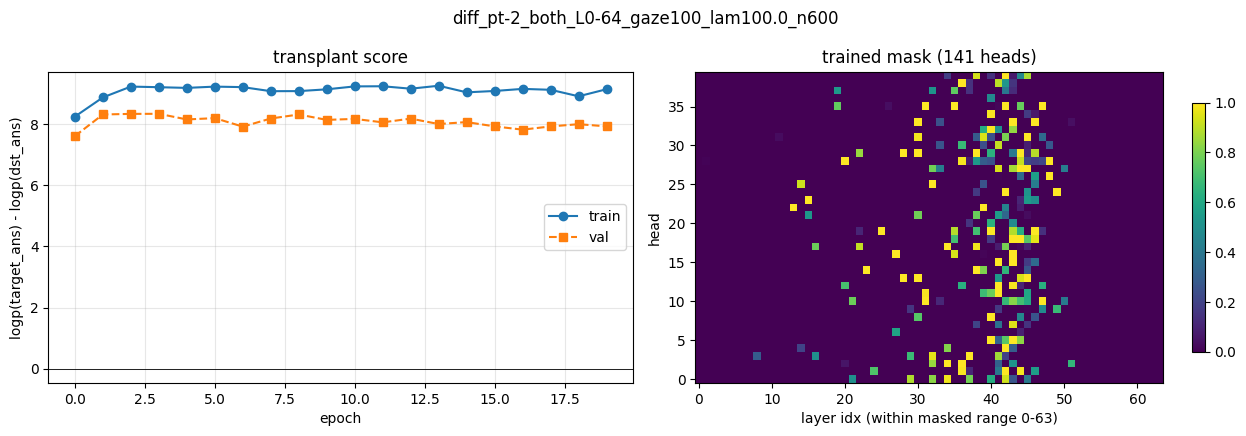

In [6]:
# ── inspect a completion-mask run ────────────────────────────────────────────
# COMPLETION_MASK_TAG = None   # None = newest; else a substring of the run tag
COMPLETION_MASK_TAG = "diff_pt-2_both_L0-64_lam50.0_n600" 
# COMPLETION_MASK_TAG = "diff_pt-2_both_L0-48_lam50.0_n600"
# 
COMPLETION_MASK_TAG = "diff_pt-2_both_L0-64_gaze100_lam100.0_n600" 


CK     = load_completion_mask(COMPLETION_MASK_TAG)
layers = [int(x) for x in CK["layers"]]
mv     = CK["mask_values"].numpy()
hist   = CK["history"]
meta   = CK["meta"]
dec    = [tuple(int(z) for z in lh) for lh in CK["decision_heads"]]
thr    = meta.get("sel_threshold", 0.9)
mask   = completion_mask_to_headmask(CK)

print(f"[{os.path.basename(CK['dir'])}]")
print(f"  layers {layers[0]}-{layers[-1]} ({len(layers)} masked) · patch_tokens={CK['patch_tokens']} · "
      f"direction={meta['direction']} · same={meta['same']} · N={meta['n_pairs']}")
print(f"  {len(dec)} decision heads (mask>{thr}) · "
      f"final train score={hist['train_score'][-1]:+.4f} · val score={hist['val_score'][-1]:+.4f}")
ranked = sorted(dec, key=lambda lh: mv[layers.index(lh[0]), lh[1]], reverse=True)
print("  top decision heads:", [f"L{l}H{h}" for (l, h) in ranked[:15]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ep = range(len(hist["train_score"]))
ax[0].plot(ep, hist["train_score"], "o-", label="train")
ax[0].plot(ep, hist["val_score"], "s--", label="val")
ax[0].axhline(0, color="k", lw=0.6)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("logp(target_ans) - logp(dst_ans)")
ax[0].set_title("transplant score"); ax[0].legend(); ax[0].grid(alpha=0.3)
im = ax[1].imshow(mv.T, aspect="auto", cmap="viridis", vmin=0, vmax=1, origin="lower")
ax[1].set_xlabel(f"layer idx (within masked range {layers[0]}-{layers[-1]})")
ax[1].set_ylabel("head"); ax[1].set_title(f"trained mask ({len(dec)} heads)")
fig.colorbar(im, ax=ax[1], shrink=0.8)
fig.suptitle(os.path.basename(CK["dir"]))
fig.tight_layout()
plt.show()

In [7]:
def get_mask_bin(heads):
    """Return a HeadMask (on CPU) with 1.0 for the given heads, 0.0 elsewhere."""
    hm = HeadMask(mt.n_layer, mt.config.num_attention_heads)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[l, h] = 1.0
    return hm

mask_bin: 141 heads = 1.0 (binary @ thr 0.5)
sel_threshold=0.5  ->  141 selected heads (of 2560 masked; 2560 mask values)
  selected: ['L42H39', 'L41H15', 'L44H29', 'L15H23', 'L35H35', 'L42H4', 'L43H5', 'L36H2', 'L30H13', 'L43H16', 'L32H25', 'L37H3', 'L31H35', 'L41H12', 'L31H10', 'L48H26', 'L20H28', 'L30H29', 'L34H2', 'L48H28'] ...


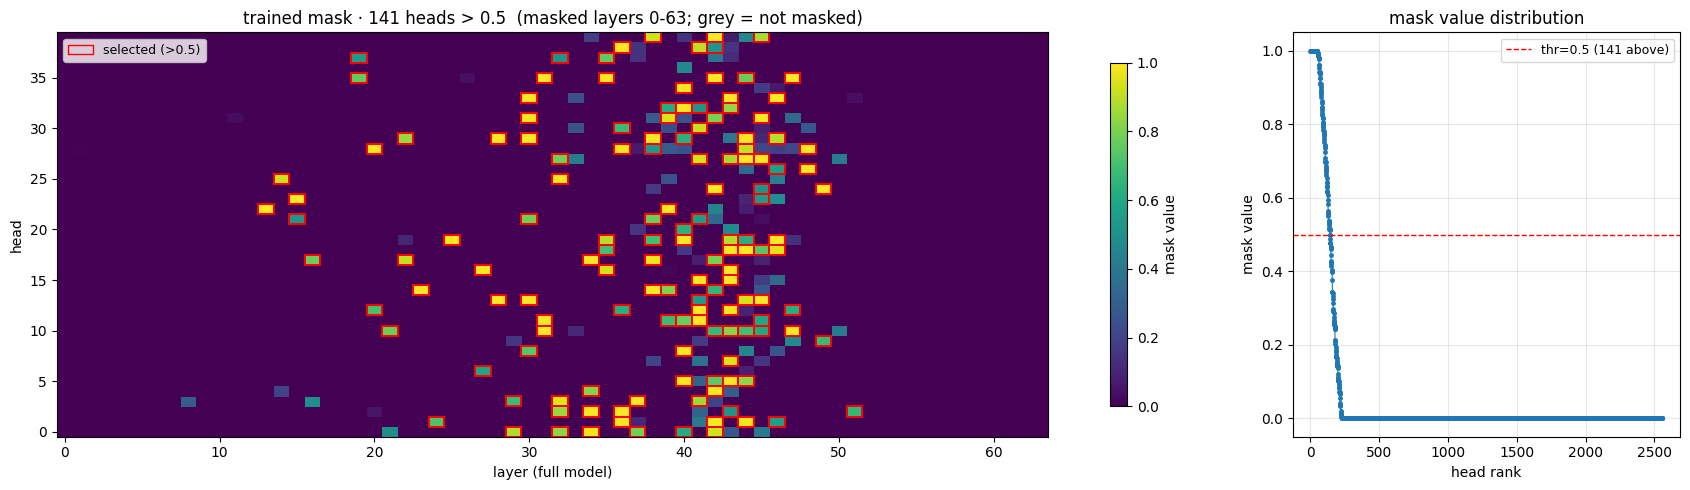

In [8]:
# ── which heads the trained mask ACTUALLY selects (mask > sel_threshold) ──────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

SEL_THRESHOLD = float(meta.get("sel_threshold", 0.9))   # editable; default mirrors trainer
n_layer_total = mt.model.config.num_hidden_layers
n_heads_total = mv.shape[1]

# place the masked-range mask values on a FULL-model grid (NaN = layer not masked)
full_mask = np.full((n_layer_total, n_heads_total), np.nan, dtype=float)
for li, L in enumerate(layers):
    full_mask[L] = mv[li]

sel_set  = {(int(l), int(h)) for l, h in np.argwhere(full_mask > SEL_THRESHOLD)}
sel_heads = sorted(sel_set)

# binary EVAL mask over the masked layers — selected heads = 1.0.
# ALWAYS used for patching/evaluation (never the continuous trained mask).
from src.goals.head_loc_attn import HeadMask
mask_bin = HeadMask(len(layers), n_heads_total)
with torch.no_grad():
    mask_bin.values.zero_()
    for (l, h) in sel_set:
        mask_bin.values[layers.index(l), h] = 1.0
print(f"mask_bin: {int(mask_bin.values.sum().item())} heads = 1.0 "
      f"(binary @ thr {SEL_THRESHOLD})")
vals = full_mask[~np.isnan(full_mask)]
print(f"sel_threshold={SEL_THRESHOLD}  ->  {len(sel_set)} selected heads "
      f"(of {len(layers) * n_heads_total} masked; {len(vals)} mask values)")
print("  selected:", [f"L{l}H{h}" for (l, h) in
      sorted(sel_set, key=lambda lh: full_mask[lh[0], lh[1]], reverse=True)[:20]],
      "..." if len(sel_set) > 20 else "")

cmap = plt.cm.viridis.copy()
cmap.set_bad("#eeeeee")                                  # un-masked layers -> light grey
fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [3.2, 1]})

im = ax[0].imshow(full_mask.T, aspect="auto", cmap=cmap, vmin=0, vmax=1,
                  origin="lower", interpolation="nearest")
for (l, h) in sel_set:
    ax[0].add_patch(plt.Rectangle((l - 0.5, h - 0.5), 1, 1, lw=1.4,
                                  edgecolor="red", facecolor="none"))
ax[0].axvline(layers[0] - 0.5, color="k", ls="--", lw=0.7)
ax[0].axvline(layers[-1] + 0.5, color="k", ls="--", lw=0.7)
ax[0].set_xlabel("layer (full model)"); ax[0].set_ylabel("head")
ax[0].set_title(f"trained mask · {len(sel_set)} heads > {SEL_THRESHOLD}  "
                f"(masked layers {layers[0]}-{layers[-1]}; grey = not masked)")
ax[0].legend(handles=[mpatches.Patch(edgecolor="red", facecolor="none",
             label=f"selected (>{SEL_THRESHOLD})")], loc="upper left", fontsize=9)
fig.colorbar(im, ax=ax[0], shrink=0.85, label="mask value")

# right: sorted mask values + threshold line -> shows the selection margin / gap
ax[1].plot(np.sort(vals)[::-1], "o-", ms=2.5, lw=0.8)
ax[1].axhline(SEL_THRESHOLD, color="red", ls="--", lw=1,
              label=f"thr={SEL_THRESHOLD} ({len(sel_set)} above)")
ax[1].set_xlabel("head rank"); ax[1].set_ylabel("mask value")
ax[1].set_title("mask value distribution"); ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

## Detecting the decision from the heads (stay vs move-on)

Functional-consequence check: *before* the downstream stay-vs-move-on choice is visible in the output, do the **selected heads' OV writes** already separate the two situations at the pivot?

**Setup** — minimal pairs (`same=True`: one spec rendered both ways, only the target line differs -> `ml`=stay, `sl`=move-on, every other condition held fixed; this is exactly what the `same` arg gives). For each selected head we read its OV write at `PIVOT_POS=-2` for stay vs move-on over `N` examples and measure cosine similarity:
- **per-pair**: `cos(stay_i, moveon_i)` within the same spec (mean +/- std over examples);
- **mean-vs-mean**: `cos(mean_i stay_i, mean_i moveon_i)`.

Low cosine => that head's representation flips with the decision (carries the signal); cosine ~= 1 => the head is indifferent to stay-vs-move-on.

In [9]:
# -- selected heads: does OV write at the pivot separate stay (ml) vs move-on (sl)? --
from torch.nn.functional import cosine_similarity as _cos
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import collect_head_steering_vecs

N_DECISION = 100
PIVOT_POS = -2

# minimal pairs: source IS dest (same spec, ml vs sl differ only at the target line)
dec_pairs = build_completion_pairs(
    mt, n_pairs=N_DECISION, direction="both", same=True,
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]), seed=2024,
)
stay_prompts = [p.source.ml_prompt for p in dec_pairs]    # incomplete target  -> stay/continue
move_prompts = [p.source.sl_prompt for p in dec_pairs]    # complete target    -> moved_on
print(f"{len(dec_pairs)} minimal pairs; reading {len(sel_heads)} selected heads at pos {PIVOT_POS}")

# per-head OV write at the pivot for both situations (left-pad => -2 aligns across lengths)
stay_tok = prepare_input(stay_prompts, tokenizer=mt, padding_side="left")
move_tok = prepare_input(move_prompts, tokenizer=mt, padding_side="left")
_, stay_h = collect_head_steering_vecs(mt, stay_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)
_, move_h = collect_head_steering_vecs(mt, move_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)

  built 25/100 pairs (27 attempts)
  built 50/100 pairs (54 attempts)
  built 75/100 pairs (79 attempts)
  built 100/100 pairs (104 attempts)
built 100 pairs from 104 attempts
100 minimal pairs; reading 141 selected heads at pos -2


In [14]:
rows = []
for (l, h) in sorted(sel_heads):
    stay = stay_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    move = move_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    per_pair = _cos(stay, move, dim=1)                       # (N,)  cos within each spec
    mean_vs_mean = _cos(stay.mean(0), move.mean(0), dim=0).item()
    rows.append((l, h, per_pair.mean().item(), per_pair.std().item(), mean_vs_mean))

rows.sort(key=lambda r: r[2])   # most-separating (lowest cosine) first
print(f"\n{'layer':>5} {'head':>5} {'per-pair cos (mean+/-std)':>26} {'mean-vs-mean cos':>18}")
for l, h, m, s, mm in rows:
    print(f"{l:5d} {h:5d} {m:>14.3f} +/-{s:<7.3f} {mm:>18.3f}")


layer  head  per-pair cos (mean+/-std)   mean-vs-mean cos
   44    28          0.120 +/-0.193                0.101
   31    10          0.129 +/-0.205                0.010
   13    22          0.174 +/-0.214                0.221
   40    32          0.177 +/-0.222                0.084
   48    26          0.178 +/-0.197                0.266
   14    25          0.179 +/-0.204                0.327
   48    28          0.181 +/-0.210                0.210
   51     2          0.207 +/-0.299                0.307
   28    13          0.228 +/-0.221                0.223
   43    16          0.246 +/-0.196                0.279
   38    29          0.247 +/-0.218                0.072
   34    17          0.261 +/-0.210                0.241
   40     5          0.266 +/-0.201                0.279
   46    26          0.274 +/-0.276                0.672
   44    13          0.279 +/-0.251                0.128
   19    35          0.289 +/-0.204                0.463
   34     2          0.290 +/

In [15]:
filtered_sel_heads = [
    (l, h)
    for (l, h), m, s, mm in zip(
        sel_heads, [r[2] for r in rows], [r[3] for r in rows], [r[4] for r in rows]
    )
    if m < 0.7
]
print(len(filtered_sel_heads), len(sel_heads))


#######################################################################
DECISION_HEADS = filtered_sel_heads
# PATCH_HEADS = sel_heads
#######################################################################
len(DECISION_HEADS)

116 141


116

## Loading Gaze Heads

In [16]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores


# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 100
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
gaze_heads = [(int(l), int(h)) for l, h in (np.unravel_index(i, gaze_scores.shape) for i in flat_idx)]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-100 gaze heads  (compare_with='mean', q_span=15)  score range [2.725, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 85 more)


mask-selected: 116  ·  gaze top-100: 100 in masked band
overlap (both): 4  ·  Jaccard within band = 0.019
  overlap heads: ['L25H19', 'L40H0', 'L42H31', 'L44H13']


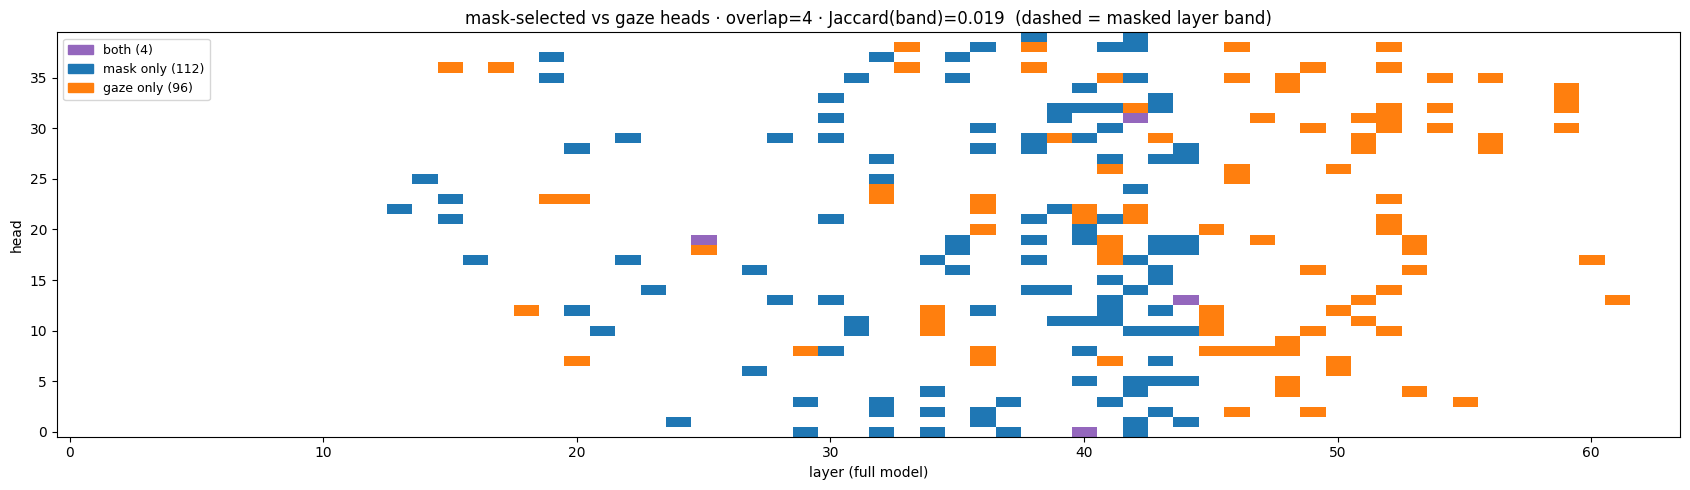

In [17]:
# ── overlap of mask-selected heads with the top-K gaze heads (§5) ─────────────
# requires `gaze_heads` from the §5 gaze-score cell (run it first).
from matplotlib.colors import ListedColormap


gaze_set  = {(int(l), int(h)) for (l, h) in gaze_heads}
PATCH_SET = set(DECISION_HEADS)
both      = PATCH_SET & gaze_set
mask_only = PATCH_SET - gaze_set
gaze_only = gaze_set - PATCH_SET

# the mask can only select WITHIN its masked layer band — restrict gaze there for a fair
# Jaccard, but plot the full picture.
band = set(layers)
gaze_in_band = {(l, h) for (l, h) in gaze_set if l in band}
jac = len(both) / max(len(PATCH_SET | gaze_in_band), 1)
print(f"mask-selected: {len(PATCH_SET)}  ·  gaze top-{len(gaze_set)}: "
      f"{len(gaze_in_band)} in masked band")
print(f"overlap (both): {len(both)}  ·  Jaccard within band = {jac:.3f}")
print("  overlap heads:", sorted(f"L{l}H{h}" for (l, h) in both))

# categorical grid: 0 none · 1 gaze-only · 2 mask-only · 3 both
cat = np.zeros((n_layer_total, n_heads_total))
for (l, h) in gaze_only: cat[l, h] = 1
for (l, h) in mask_only: cat[l, h] = 2
for (l, h) in both:      cat[l, h] = 3
cats_cmap = ListedColormap(["#ffffff", "#ff7f0e", "#1f77b4", "#9467bd"])

fig, ax = plt.subplots(figsize=(17, 5))
ax.imshow(cat.T, aspect="auto", cmap=cats_cmap, vmin=0, vmax=3,
          origin="lower", interpolation="nearest")
ax.axvline(layers[0] - 0.5, color="k", ls="--", lw=0.7)
ax.axvline(layers[-1] + 0.5, color="k", ls="--", lw=0.7)
ax.set_xlabel("layer (full model)"); ax.set_ylabel("head")
ax.set_title(f"mask-selected vs gaze heads · overlap={len(both)} · "
             f"Jaccard(band)={jac:.3f}  (dashed = masked layer band)")
handles = [mpatches.Patch(color=c, label=lab) for c, lab in [
    ("#9467bd", f"both ({len(both)})"),
    ("#1f77b4", f"mask only ({len(mask_only)})"),
    ("#ff7f0e", f"gaze only ({len(gaze_only)})"),
]]
ax.legend(handles=handles, loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

## Causal Experiments

In [18]:
from src.goals.completion_pairs import build_completion_pairs, LEG_STYLES
##############################################################################################
# leg the mask was trained on (fall back to ml->sl if the run used direction='both')
HP_DIRECTION = "sl->ml"
##############################################################################################
if HP_DIRECTION not in LEG_STYLES:
    raise ValueError(f"got {HP_DIRECTION=}, valid options: {list(LEG_STYLES.keys())}")

ss = LEG_STYLES[HP_DIRECTION][
    "src_style"
]  # source donates this style (== dest's target)
ds = LEG_STYLES[HP_DIRECTION]["dst_style"]  # dest runs (clean) this style
PATCH_POS = int(CK["patch_tokens"][0]) if len(CK["patch_tokens"]) == 1 else POS

In [1]:
ss

NameError: name 'ss' is not defined

### Single Contrastive Pair

In [23]:
# ── one validated (source, dest) transplant pair + cached source heads ─────────
from src.goals.head_loc_attn import (
    get_o_proj_inputs_batch,
    make_head_replacement_patch_interface,
)
from src.goals.goalscope import headpatched_generate
from src.functional import generate_with_patch

assert sel_set, (
    "no heads above SEL_THRESHOLD — lower it in the §6 selection cell or retrain"
)

# sample with the SAME builder + gates the trainer used (token-aligned at PATCH_POS)
hp = build_completion_pairs(
    mt,
    n_pairs=1,
    direction=HP_DIRECTION,
    same=bool(meta.get("same", False)),
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]),
    seed=1123,
)[0]
src_prompt = hp.source.prompt(ss)
dst_prompt = hp.dest.prompt(ds)
target_ans = hp.dest.ans(
    ss
)  # dest's counterfactual (flip) token — a good patch -> this
dst_ans = hp.dest.ans(ds)  # dest's clean verdict token


def _tok(i):
    return mt.tokenizer.decode(i)


print(
    f"leg {HP_DIRECTION}  ·  src_style={ss}  dst_style={ds}  ·  patch POS={PATCH_POS}"
)
print(f"  dst_ans (clean)   = {_tok(dst_ans)!r}")
print(f"  target_ans (flip) = {_tok(target_ans)!r}")

# cache the SOURCE o_proj inputs at PATCH_POS for the masked layers -> (n_layers, n_embd)
src_cache = get_o_proj_inputs_batch(
    mt, [src_prompt], layers, token_positions=[PATCH_POS]
)
src_o_proj_inps = torch.stack(
    [src_cache[l][0, 0] for l in layers]
)  # (n_layers, n_embd)
print("src_o_proj_inps:", tuple(src_o_proj_inps.shape))

built 1 pairs from 1 attempts
leg sl->ml  ·  src_style=sl  dst_style=ml  ·  patch POS=-2
  dst_ans (clean)   = ' b'
  target_ans (flip) = ' c'
src_o_proj_inps: (64, 5120)


In [24]:
source_gen = generate_with_patch(
    mt,
    inputs=src_prompt,
    n_gen_per_prompt=1,
    max_new_tokens=16,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{escape(src_prompt)}[/white][medium_orchid1]{escape(source_gen)}[/medium_orchid1]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is coprime with 12
2. n has at least 4 digits
3. n is a perfect cube
4. the sum of n's proper divisors is greater than n
5. n is divisible by 4
6. n is a perfect square

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = math.gcd(n, 12)    
    a = a == 1    
    b = len(str(abs(n)))    
    b = b >= 4    
    c = round(abs(n) ** (1 / 3)) ** 3 == abs(n)    
    d = n > 0 and sum(d for d in range(1, abs(n)) if n % d == 0) > n    
    e = n % 4 == 0    
    f = round(abs(n

In [25]:
# ── clean dest generation  vs  head-patched dest generation ───────────────────
from src.functional import generate_with_patch

HP_N_GEN = 24
dst_tok = prepare_input(dst_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dst_tok,
    n_gen_per_prompt=1,
    max_new_tokens=HP_N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]

# patch the trained heads' OV write at the pivot (PATCH_POS) on the prefill only
# (n_steer_tokens=1) — matches how the mask was trained.
patched_gen = headpatched_generate(
    mt,
    dest_inputs=dst_tok,
    src_o_proj_inps=src_o_proj_inps,
    mask=get_mask_bin(DECISION_HEADS),            # binarized selected heads (eval)
    layers=layers,
    max_new_tokens=HP_N_GEN,
    n_steer_tokens=1,
    patch_input_positions=[PATCH_POS],
)

rich_print(
    f"[bold]clean  [/bold] [white]{escape(dst_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)
rich_print(
    f"[bold]patched {len(DECISION_HEADS)}[/bold] [white]{escape(dst_prompt)}[/white]"
    f"[salmon1]{escape(patched_gen)}[/salmon1]"
)
rich_print(f"target_ans (desired flip) = [bold]{escape(repr(_tok(target_ans)))}[/bold]")

clean   <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a palindrome (its digits read the same forwards and backwards)
2. n has more than 4 divisors
3. n is smaller than the number obtained by reversing its digits

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = str(abs(n))    
    a = a == a[::-1]    
    b = sum(1 for d in range(1, abs(n) + 1) if n % d == 0)    
    b = b > 4    
    c = n < int(str(abs(n))[::-1])    
    print(f

patched 116 <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a palindrome (its digits read the same forwards and backwards)
2. n has more than 4 divisors
3. n is smaller than the number obtained by reversing its digits

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = str(abs(n))    
    a = a == a[::-1]    
    b = sum(1 for d in range(1, abs(n) + 1) if n % d == 0)    
    c = n < int(str(abs(n))[::-1])    
    print(f"Palindrome: {a}, More than

target_ans (desired flip) = ' c'

In [ ]:
# # ── clean dest attention of the decision heads (pivot POS marked) ─────────────
# from src.attention import get_attention_matrices, show_interactive_attention

# P = len(dst_tok.input_ids[0])  # dest-prompt length (gen starts at this index)
# pivot_abs = P + PATCH_POS  # absolute index of the patched pivot in prompt+gen

# clean_full = dst_prompt + clean_gen
# # guard against retokenization drift so pivot_abs points at the right token
# _full_ids = prepare_input(prompts=clean_full, tokenizer=mt).input_ids[0]
# assert _full_ids[:P].tolist() == dst_tok.input_ids[0].tolist(), (
#     "retokenization drift: dst_prompt is not a clean prefix of dst_prompt+clean_gen"
# )

# clean_attn = get_attention_matrices(input=clean_full, mt=mt, value_weighted=True)
# show_interactive_attention(
#     attn_info=clean_attn,
#     selected_heads=gaze_heads,
#     start_from=0,
#     agg="mean",
#     normalize="row_max",
#     cmap="Greens",
#     title=f"Clean dest attention — {len(gaze_heads)} decision heads",
#     track_conditions=hp.dest.spec,
#     height=None,
#     intervened_positions=[pivot_abs],
# )

In [ ]:
# # ── head-patched dest attention via the head-replacement patch_interface ──────
# patched_full = dst_prompt + patched_gen
# _pf_ids = prepare_input(prompts=patched_full, tokenizer=mt).input_ids[0]
# assert _pf_ids[:P].tolist() == dst_tok.input_ids[0].tolist(), (
#     "retokenization drift: dst_prompt is not a clean prefix of dst_prompt+patched_gen"
# )

# # bespoke patch_interface: applies the SAME per-head o_proj transplant used for steering,
# # at the pivot, so the returned attention/logits reflect the head-patched run.
# hp_patch_interface = make_head_replacement_patch_interface(
#     src_o_proj_inps,
#     get_mask_bin(DECISION_HEADS),
#     layers,
#     patch_positions=[pivot_abs],
# )
# patched_attn = get_attention_matrices(
#     input=patched_full,
#     mt=mt,
#     value_weighted=True,
#     patch_interface=hp_patch_interface,
# )
# show_interactive_attention(
#     attn_info=patched_attn,
#     selected_heads=gaze_heads,
#     start_from=0,
#     agg="mean",
#     normalize="row_max",
#     cmap="Reds",
#     title=f"Head-patched dest attention — {len(gaze_heads)} decision heads",
#     track_conditions=hp.dest.spec,
#     height=None,
#     intervened_positions=[pivot_abs],
# )

### Mean (general) signal — replace vs additive steering

§6 transplants a *single* matched source. Here we average the selected heads' OV write at `POS` over **N source runs** → a context-general signal (general **stay** for `ml->sl`, **move-on** for `sl->ml`), then intervene on the same dest two ways (cf. `apply_goalscope` strategies):

- **(i) replace** — binarized selected heads (`mask_bin`); their o_proj outputs at `POS` swapped for the mean (`headpatched_generate`).
- **(ii) additive** — the selected heads' mean residual contribution `Σ_h mean_oproj_h @ W_o_h` becomes a steering vector, added across `ADD_LAYERS` à la §5.

Selected heads are **always binarized** at `SEL_THRESHOLD`.

In [26]:
# ── mean (general) signal: average the source OV write at POS over N sources ──
# cached to NB_CACHE_DIR; recomputed only when OVERWRITE or no cache file present
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import get_o_proj_inputs_batch

N_MEAN_SRC = 300
MEAN_SRC_BATCH = 16

rich_print(f"[bold]{HP_DIRECTION}, at POS={PATCH_POS}[/bold]")

_mean_cfg = dict(
    model=MODEL_NAME, kind="mean_signal", direction=HP_DIRECTION, n_src=N_MEAN_SRC,
    same=bool(meta.get("same", False)),
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]),
    patch_pos=int(PATCH_POS), layers=list(int(l) for l in layers), seed=1234,
)
_mean_path = os.path.join(
    NB_CACHE_DIR,
    f"mean_signal_{HP_DIRECTION.replace('->', '_')}_N{N_MEAN_SRC}_{_key(**_mean_cfg)}.pt",
)

if not OVERWRITE and os.path.exists(_mean_path):
    mean_signal = torch.load(_mean_path)
    print(f"loaded mean_signal from cache: {_mean_path}")
    print("mean_signal:", tuple(mean_signal.shape))
else:
    mean_pairs = build_completion_pairs(
        mt, n_pairs=N_MEAN_SRC, direction=HP_DIRECTION,
        same=bool(meta.get("same", False)),
        patch_tokens=tuple(int(t) for t in CK["patch_tokens"]),
        seed=1234,
    )
    mean_src_prompts = [p.source.prompt(ss) for p in mean_pairs]
    _sig_name = "stay" if ss == "ml" else "move-on"
    print(f"sampled {len(mean_src_prompts)} sources (style={ss}) for the mean '{_sig_name}' signal")

    # chunked o_proj caching at PATCH_POS, accumulated -> mean over sources
    _acc, _n = None, 0
    for i in range(0, len(mean_src_prompts), MEAN_SRC_BATCH):
        chunk = mean_src_prompts[i:i + MEAN_SRC_BATCH]
        c = get_o_proj_inputs_batch(mt, chunk, layers, token_positions=[PATCH_POS])
        stk = torch.stack([c[l][:, 0] for l in layers], dim=1)   # (b, n_layers, n_embd)
        _acc = stk.sum(0) if _acc is None else _acc + stk.sum(0)
        _n += stk.shape[0]
    mean_signal = _acc / _n            # (n_layers, n_embd) — context-general source signal
    torch.save(mean_signal, _mean_path)
    print("mean_signal:", tuple(mean_signal.shape), "from", _n, "sources")
    print(f"saved mean_signal to cache: {_mean_path}")


sl->ml, at POS=-2

loaded mean_signal from cache: /disk/u/arnab/Codes/Projects/goals/results/notebook_cache/mean_signal_sl_ml_N300_00ed331a0f.pt
mean_signal: (64, 5120)


In [ ]:
from src.functional import generate_with_patch

#####################################################################
NAMING = "letters"  # "letters" | "natural" | "indexed"
N_GEN = 32
# PATCH_HEADS = sel_heads
DECISION_HEADS = filtered_sel_heads
#####################################################################

style = "multiline" if ss == "sl" else "singleline"

example = build_example(
    mt=mt,
    rng=random.Random(135),
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style=style,
    naming=NAMING,
)
prompt = replace_in_code_newline_with_tabnewline(example["full_prompt"]) + "   "

tokenized = prepare_input(prompt, tokenizer=mt, padding_side="left")
P = len(tokenized.input_ids[0])
pivot_abs = P + PATCH_POS  # absolute index of the patched pivot in prompt+gen

clean_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean        [/bold] [white]{escape(prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

In [ ]:
from src.goals.goalscope import headpatched_generate

# ── (i) REPLACE: swap selected heads' OV output at POS for the MEAN signal ────
mean_replace_gen = headpatched_generate(
    mt,
    dest_inputs=tokenized,
    src_o_proj_inps=mean_signal,
    mask=get_mask_bin(DECISION_HEADS),  # binarized selected heads
    layers=layers,
    max_new_tokens=N_GEN,
    n_steer_tokens=1,  # patch the prefill pivot only (matches §6)
    patch_input_positions=[PATCH_POS],
)

rich_print(
    f"[bold]mean-replace ({len(DECISION_HEADS)}) [/bold] [white]{escape(prompt)}[/white]"
    f"[salmon1]{escape(mean_replace_gen)}[/salmon1]"
)

In [ ]:
from src.attention import get_attention_matrices, show_interactive_attention

clean_attn = get_attention_matrices(
    input=prompt + clean_gen,
    mt=mt,
    value_weighted=True,
)
show_interactive_attention(
    attn_info=clean_attn,
    selected_heads=gaze_heads,
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Greens",
    title=f"Mean-replace dest attention — {len(gaze_heads)} heads",
    track_conditions=example["spec"],
    height=None,
    intervened_positions=[pivot_abs],
)

In [ ]:
from src.goals.head_loc_attn import make_head_replacement_patch_interface

# ── (i) REPLACE attention: mean-signal head patch at the pivot ────────────────
mean_replace_full = prompt + mean_replace_gen
_mr_ids = prepare_input(prompts=mean_replace_full, tokenizer=mt).input_ids[0]
assert _mr_ids[:P].tolist() == tokenized.input_ids[0].tolist(), (
    "retokenization drift: dst_prompt is not a clean prefix of dst_prompt+mean_replace_gen"
)

mean_replace_iface = make_head_replacement_patch_interface(
    mean_signal,
    get_mask_bin(DECISION_HEADS),
    layers,
    patch_positions=[pivot_abs],
)
mean_replace_attn = get_attention_matrices(
    input=mean_replace_full,
    mt=mt,
    value_weighted=True,
    patch_interface=mean_replace_iface,
)
show_interactive_attention(
    attn_info=mean_replace_attn,
    selected_heads=gaze_heads,
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Reds",
    title=f"Mean-replace dest attention — {len(gaze_heads)} heads",
    track_conditions=example["spec"],
    height=None,
    intervened_positions=[pivot_abs],
)

In [ ]:
import baukit

n_heads_model = mt.model.config.num_attention_heads
head_dim = mt.n_embd // n_heads_model
# aggregate  Σ_h  mean_oproj_h @ W_o_h  over the binarized selected heads -> (n_embd,)
sv = torch.zeros(mt.n_embd, dtype=torch.float32)
for (l, h) in DECISION_HEADS:
    li = layers.index(l)
    W_o = baukit.get_module(
        mt._model, mt.attn_module_name_format.format(l) + ".o_proj"
    ).weight.detach().float().cpu()                                  # (n_embd, n_embd)
    h_in = mean_signal[li][h * head_dim:(h + 1) * head_dim]          # (head_dim,)
    sv += h_in @ W_o[:, h * head_dim:(h + 1) * head_dim].t()         # (n_embd,)
print("steering vec sv:", tuple(sv.shape), "from", len(DECISION_HEADS), "heads")

In [ ]:
# ── (ii) ADDITIVE: selected heads' mean residual contribution -> steering vec ─
from src.functional import get_hs, PatchSpec, generate_with_patch

ADD_LAYERS = list(range(35, 50))   # where the aggregated vec is injected (cf. §5)
ADD_COEFF  = 0.3                   # §5-style norm-matched scale
ADD_N_STEER = 1                    # patch the prefill pivot only (matches the replace leg)

# steer like §5: add coeff·‖h‖·sv/‖sv‖ at POS (prefill) + last token (decode) over ADD_LAYERS
src_hs_dst = get_hs(
    mt=mt, input=tokenized,
    locations=[(mt.layer_name_format.format(L), PATCH_POS) for L in ADD_LAYERS],
    return_dict=True,
)
add_patches = []
add_pos = []
for L in ADD_LAYERS:
    h_at = src_hs_dst[(mt.layer_name_format.format(L), PATCH_POS)]
    vec = sv.to(h_at.device) * ADD_COEFF * h_at.norm() / (sv.norm() + 1e-8)
    add_patches.append(PatchSpec(
        location=(mt.layer_name_format.format(L), PATCH_POS),
        patch=vec, strategy="add", on_pass="first"))
    add_pos = [P - 2]

    # add_patches.append(PatchSpec(
    #     location=(mt.layer_name_format.format(L), -1),
    #     patch=vec, strategy="add", on_pass="all"))
    # add_pos.append(P - 1)

mean_add_gen = generate_with_patch(
    mt, inputs=tokenized, n_gen_per_prompt=1, max_new_tokens=HP_N_GEN,
    do_sample=False, remove_prefix=True, patches=add_patches,
    n_steer_tokens=ADD_N_STEER, patch_interface="baukit",
)[0]
rich_print(f"[bold]clean        [/bold] [white]{escape(prompt)}[/white]"
           f"[sea_green3]{escape(clean_gen)}[/sea_green3]")
rich_print(f"[bold]mean-additive[/bold] [white]{escape(prompt)}[/white]"
           f"[salmon1]{escape(mean_add_gen)}[/salmon1]")

In [ ]:
# ── (ii) ADDITIVE attention: steering vec added at the pivot (single forward) ─
mean_add_full = prompt + mean_add_gen
_ma_ids = prepare_input(prompts=mean_add_full, tokenizer=mt).input_ids[0]
assert _ma_ids[:P].tolist() == tokenized.input_ids[0].tolist(), \
    "retokenization drift: prompt is not a clean prefix of prompt+mean_add_gen"

# replicate the prefill steering in one forward pass: POS (-> P-2) and last prompt tok (P-1)

add_attn_patches = []
for L in ADD_LAYERS:
    h_at = src_hs_dst[(mt.layer_name_format.format(L), PATCH_POS)]
    vec = sv.to(h_at.device) * ADD_COEFF * h_at.norm() / (sv.norm() + 1e-8)
    for pos in add_pos:
        add_attn_patches.append(PatchSpec(
            location=(mt.layer_name_format.format(L), pos),
            patch=vec, strategy="add", on_pass="first"))

mean_add_attn = get_attention_matrices(
    input=mean_add_full, mt=mt, value_weighted=True, 
    patches=add_attn_patches,
)
show_interactive_attention(
    attn_info=mean_add_attn, selected_heads=gaze_heads, start_from=0,
    agg="mean", normalize="row_max", cmap="Reds",
    title=f"Mean-additive (steered) dest attention — {len(gaze_heads)} heads",
    track_conditions=example["spec"],
    height=None, intervened_positions=add_pos,
)

## Detector (apply everywhere)

In [27]:
from torch.nn.functional import cosine_similarity
from src.attention import _safe_token
from circuitsvis.tokens import colored_tokens
from IPython.display import display

PROMPT = prompt + clean_gen
TARGET_LAYER = 37

tokenized = prepare_input(PROMPT, tokenizer=mt, padding_side="left")
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[
        (mt.layer_name_format.format(TARGET_LAYER), token_idx)
        for token_idx in range(tokenized.input_ids.shape[1])
    ],
    return_dict=True,
)
scores_per_token = []

for token_idx in range(tokenized.input_ids.shape[1]):
    h = hs[(mt.layer_name_format.format(TARGET_LAYER), token_idx)]
    patch_h = torch.Tensor(V_stop[TARGET_LAYER]).to(h.device)       # <--------
    # patch_h = sv.to(h.device) * h.norm() / (sv.norm() + 1e-8)
    score = cosine_similarity(h, patch_h, dim=0).item()
    scores_per_token.append(score)


tokens = [
    _safe_token(mt.tokenizer.decode(tok))
    # for tok in _demo_lat.gen_ids
    for tok in tokenized.input_ids[0].tolist()
]

# print(PROMPT, )
display(
    colored_tokens(
        tokens, scores_per_token, positive_color="seagreen", negative_color="firebrick"
    )
)

NameError: name 'prompt' is not defined

In [28]:
# ── head-output detector: cosine(Σ_{selected heads} head_out(token), target dir) ──
# Same idea as the residual detector above, but the per-token vector is the AGGREGATED
# OV write of the SELECTED heads (Σ_h o_proj_in_h @ W_o_h), not a single layer's residual.
# collect_head_steering_vecs returns exactly that sum per token position (residual space).
from src.goals.head_loc_attn import collect_head_steering_vecs

PROMPT = prompt + clean_gen
tokenized = prepare_input(PROMPT, tokenizer=mt, padding_side="left")
n_pos = tokenized.input_ids.shape[1]

# target direction: the aggregated MEAN selected-head output (general signal; from §6.1
# additive cell). Any (n_embd) residual-space direction works here, e.g. V_stop[L].
target_dir = sv

# aggregated selected-head output at every token position -> (n_pos, n_embd)
agg_head_out = collect_head_steering_vecs(
    mt=mt, src_tokenized=tokenized,
    selected_heads=sel_heads, token_positions=list(range(n_pos)),
)[0]

td = target_dir.to(agg_head_out.device).float()
scores_per_token = [
    cosine_similarity(agg_head_out[i], td, dim=0).item() for i in range(n_pos)
]

tokens = [_safe_token(mt.tokenizer.decode(tok)) for tok in tokenized.input_ids[0].tolist()]
display(
    colored_tokens(
        tokens, scores_per_token, positive_color="seagreen", negative_color="firebrick"
    )
)

NameError: name 'prompt' is not defined

### MoE decision detector — per-head move-on directions

Instead of one `target_dir=sv` on the *summed* head output, treat the top decision heads as a **mixture of experts**. Per head: `head_move = E[out(PIVOT|sl)] - E[out(PIVOT|ml)]` (move-on minus stay). Per token: `score_{l,h}(t) = cos(head_move_{l,h}, out_{l,h}(t))`, then mean over the selected heads. Self-contained (its own pairs + detection example); leaves `DECISION_HEADS` untouched. Head set chosen by `MOE_SELECTION` = `TOP_K` (K lowest-cosine heads) or `THRESHOLD` (per-pair cos below a max value).

In [29]:
# -- MoE detector: per-head move-on directions + head selection (self-contained) --
# Duplicates the §Decision stay/move OV extraction for the move-on (sl - ml) target,
# then picks detector heads by separation. Does NOT touch DECISION_HEADS.
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import collect_head_steering_vecs
from torch.nn.functional import cosine_similarity as _cos

MOE_N_PAIRS = 50
MOE_PIVOT_POS = -2

# head selection: lower per-pair cosine = more decision-separating
MOE_SELECTION = "TOP_K"     # "TOP_K" | "THRESHOLD"
MOE_TOP_K = 20              # used when TOP_K: keep the K lowest-cosine heads
MOE_THRESHOLD = 0.7         # used when THRESHOLD: keep heads with per-pair cos < this (max)

# minimal pairs (same spec; ml=stay vs sl=move-on differ only at the target line)
_moe_pairs = build_completion_pairs(
    mt, n_pairs=MOE_N_PAIRS, direction="both", same=True,
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]), seed=2024,
)
_stay_p = [p.source.ml_prompt for p in _moe_pairs]   # stay
_move_p = [p.source.sl_prompt for p in _moe_pairs]    # move-on
_stay_tok = prepare_input(_stay_p, tokenizer=mt, padding_side="left")
_move_tok = prepare_input(_move_p, tokenizer=mt, padding_side="left")
_, _stay_h = collect_head_steering_vecs(mt, _stay_tok, sel_heads, [MOE_PIVOT_POS], return_individual_heads=True)
_, _move_h = collect_head_steering_vecs(mt, _move_tok, sel_heads, [MOE_PIVOT_POS], return_individual_heads=True)

# per head: move-on direction + per-pair cosine separation
head_move, sep = {}, {}
for (l, h) in sel_heads:
    stay = _stay_h[(l, h)][:, 0, :].float()
    move = _move_h[(l, h)][:, 0, :].float()
    head_move[(l, h)] = move.mean(0) - stay.mean(0)        # (n_embd) move-on target dir
    sep[(l, h)] = _cos(stay, move, dim=1).mean().item()    # per-pair cos (lower = better)

ranked = sorted(sel_heads, key=lambda lh: sep[lh])         # most-separating first
if MOE_SELECTION == "TOP_K":
    MOE_HEADS = ranked[:MOE_TOP_K]
elif MOE_SELECTION == "THRESHOLD":
    MOE_HEADS = [lh for lh in ranked if sep[lh] < MOE_THRESHOLD]
else:
    raise ValueError(f"unknown MOE_SELECTION={MOE_SELECTION!r}")
assert MOE_HEADS, "no heads selected — relax MOE_THRESHOLD / MOE_TOP_K"
print(f"MoE detector: {len(MOE_HEADS)} of {len(sel_heads)} heads via {MOE_SELECTION} "
      f"(per-pair cos {sep[MOE_HEADS[0]]:.3f}..{sep[MOE_HEADS[-1]]:.3f})")
print("  heads:", [f"L{l}H{h}" for (l, h) in MOE_HEADS])


  built 25/50 pairs (27 attempts)
  built 50/50 pairs (54 attempts)
built 50 pairs from 54 attempts
MoE detector: 20 of 141 heads via TOP_K (per-pair cos 0.136..0.326)
  heads: ['L31H10', 'L44H28', 'L13H22', 'L51H2', 'L48H26', 'L14H25', 'L48H28', 'L40H32', 'L28H13', 'L43H16', 'L40H5', 'L34H17', 'L38H29', 'L30H29', 'L34H2', 'L46H1', 'L15H21', 'L44H13', 'L19H35', 'L46H26']


In [32]:
# -- MoE detection: mean over experts of cos(head_move, out(t)) at every token --
# self-contained detection example (fresh prompt + clean greedy generation)
_moe_style = "multiline" if ss == "sl" else "singleline"
_moe_example = build_example(
    mt=mt, rng=random.Random(321), target_slot=2, n_conditions=4,
    mode="chat", style=_moe_style, naming="letters",
)
# _moe_prompt = _moe_example["full_prompt"]
_moe_prompt = "Here is an implementation of merge sort:\n<code>\n"
# _moe_prompt = replace_in_code_newline_with_tabnewline(_moe_prompt) + "   "
_moe_tok = prepare_input(_moe_prompt, tokenizer=mt, padding_side="left")
_moe_gen = generate_with_patch(
    mt, inputs=_moe_tok, n_gen_per_prompt=1, max_new_tokens=256,
    do_sample=False, remove_prefix=True,
)[0]

DETECT = _moe_prompt + _moe_gen
det_tok = prepare_input(DETECT, tokenizer=mt, padding_side="left")
n_pos = det_tok.input_ids.shape[1]

# per-head OV output at every token position for the MoE heads
_, det_head_out = collect_head_steering_vecs(
    mt=mt, src_tokenized=det_tok, selected_heads=sorted(MOE_HEADS),
    token_positions=list(range(n_pos)), return_individual_heads=True,
)

# each head = expert: score_{l,h}(t) = cos(head_move_{l,h}, out_{l,h}(t)); mean over experts
per_head = torch.stack([
    _cos(det_head_out[(l, h)][0].float(), head_move[(l, h)].float().unsqueeze(0), dim=1)
    for (l, h) in MOE_HEADS
])                                          # (n_heads, n_pos)
scores_per_token = per_head.mean(0).tolist()   # mixture-of-experts aggregate

tokens = [_safe_token(mt.tokenizer.decode(tok)) for tok in det_tok.input_ids[0].tolist()]
display(colored_tokens(tokens, scores_per_token, positive_color="seagreen", negative_color="firebrick"))
